In [ ]:
%pip install -q hmmlearn graphviz

Stări: ['Dificil', 'Mediu', 'Usor']
Observații: ['FB', 'B', 'S', 'NS']


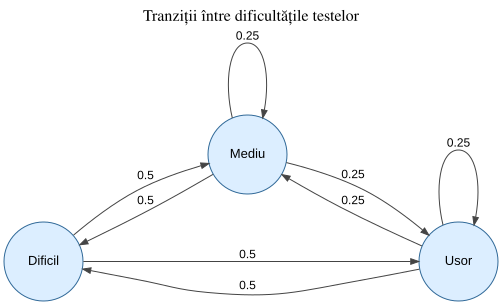

In [ ]:
import numpy as np
from hmmlearn.hmm import CategoricalHMM
from graphviz import Digraph
from IPython.display import display

stari = ["Dificil", "Mediu", "Usor"]
note = ["FB", "B", "S", "NS"]

pi = np.array([1/3, 1/3, 1/3])

A = np.array([
    [0.0, 0.50, 0.50],
    [0.5, 0.25, 0.25],
    [0.5, 0.25, 0.25]
])


B = np.array([
    [0.10, 0.20, 0.40, 0.30],
    [0.15, 0.25, 0.50, 0.10],
    [0.20, 0.30, 0.40, 0.10]
])

model = CategoricalHMM(
    n_components=3,
    n_features=4,
    init_params=""
)

model.startprob_ = pi
model.transmat_ = A
model.emissionprob_ = B

print("Stări:", stari)
print("Observații:", note)


graf = Digraph("Diagrama_HMM")

graf.attr(
    rankdir="LR",
    nodesep="1.0",
    ranksep="1.5",
    bgcolor="white",
    label="Tranziții între dificultățile testelor",
    labelloc="t",
    fontsize="16"
)

graf.attr(
    "node",
    shape="circle",
    style="filled",
    fillcolor="#DCEEFF",
    color="#306998",
    fontname="Arial",
    fontsize="13",
    width="1.1"
)

graf.attr(
    "edge",
    color="#444444",
    fontname="Arial",
    fontsize="12",
    arrowsize="0.8"
)

for stare in stari:
    graf.node(stare)

for i in range(len(stari)):
    for j in range(len(stari)):
        probabilitate = model.transmat_[i, j]

        if probabilitate > 0:
            graf.edge(
                stari[i],
                stari[j],
                label=str(probabilitate)
            )

display(graf)

In [ ]:
note_observate = [
    "FB", "FB", "S", "B", "B", "S",
    "B", "B", "NS", "B", "B", "S"
]

cod_nota = {
    "FB": 0,
    "B": 1,
    "S": 2,
    "NS": 3
}

observatii = np.array(
    [cod_nota[nota] for nota in note_observate]
).reshape(-1, 1)


log_prob_comuna, secventa_stari = model.decode(
    observatii,
    algorithm="viterbi"
)

# Funcția returnează:
#secventa_stari: codurile dificultăților estimate;
#log_prob_comuna: logaritmul probabilității comune a secvenței optime și a notelor observate.

log_prob_note = model.score(observatii)

prob_comuna = np.exp(log_prob_comuna)
prob_note = np.exp(log_prob_note)

prob_conditionata = np.exp(log_prob_comuna - log_prob_note)


print("Rezultatul pentru fiecare test:\n")

for i in range(len(note_observate)):
    print(
        f"Testul {i + 1}: "
        f"nota = {note_observate[i]}, "
        f"dificultate estimată = {stari[secventa_stari[i]]}"
    )

print("\nSecvența de dificultăți:")
print(" → ".join(stari[i] for i in secventa_stari))

print(f"\nP(dificultăți optime și note) = {prob_comuna:.12e}")
print(f"P(note) = {prob_note:.12e}")
print(f"P(dificultăți optime | note) = {prob_conditionata:.12e}")
print(f"Probabilitatea condiționată: {prob_conditionata * 100:.6f}%")

Rezultatul pentru fiecare test:

Testul 1: nota = FB, dificultate estimată = Usor
Testul 2: nota = FB, dificultate estimată = Usor
Testul 3: nota = S, dificultate estimată = Dificil
Testul 4: nota = B, dificultate estimată = Usor
Testul 5: nota = B, dificultate estimată = Dificil
Testul 6: nota = S, dificultate estimată = Mediu
Testul 7: nota = B, dificultate estimată = Dificil
Testul 8: nota = B, dificultate estimată = Usor
Testul 9: nota = NS, dificultate estimată = Dificil
Testul 10: nota = B, dificultate estimată = Usor
Testul 11: nota = B, dificultate estimată = Dificil
Testul 12: nota = S, dificultate estimată = Mediu

Secvența de dificultăți:
Usor → Usor → Dificil → Usor → Dificil → Mediu → Dificil → Usor → Dificil → Usor → Dificil → Mediu

P(dificultăți optime și note) = 2.109375000000e-11
P(note) = 7.325942897172e-08
P(dificultăți optime | note) = 2.879322197303e-04
Probabilitatea condiționată: 0.028793%
